<a href="https://colab.research.google.com/github/buntyedutainer/allocation-optimizer/blob/main/Day02_Fake_Data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Today we'll build a fake but realistic dataset, so every method you test later has something meaningful to work on.

Two ideas for today

Idea 1: synthetic data. Because we don't want to use real people's information, we generate students and preferences with code. They're made up, but they follow rules we choose: some projects are more popular than others, and students tend to prefer projects that fit their skills. A seed is a starting number for the random generator. The same seed gives exactly the same "random" data every time, so your results are repeatable.

Idea 2: ranked preferences and limited places. Each student ranks their top 5 projects (rank 1 = favourite), and each project has a fixed number of places (capacity). When more students want a project than it has places, some will be disappointed. That conflict is what makes the problem hard.

The Ten projects. Each has a title, the skills it needs, the number of places, and an "appeal" score from 0 to 1 for how popular it is with students.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SKILLS = ["Python", "Data analysis", "Web", "Design", "Writing", "Communication"]

projects = pd.DataFrame([
    ("P01", "Data Dashboard",        ["Data analysis", "Python"],               4, 0.9),
    ("P02", "Web Portal",            ["Web", "Design"],                         4, 0.5),
    ("P03", "Chatbot Helper",        ["Python", "Communication"],               3, 1.0),
    ("P04", "Learning Content",      ["Writing", "Design"],                     5, 0.3),
    ("P05", "Survey Analysis",       ["Data analysis", "Writing"],              5, 0.4),
    ("P06", "Mobile App",            ["Web", "Python"],                         3, 0.8),
    ("P07", "Community Outreach",    ["Communication", "Writing"],              6, 0.2),
    ("P08", "UX Research",           ["Design", "Communication"],               5, 0.5),
    ("P09", "Automation Scripts",    ["Python", "Data analysis"],               5, 0.6),
    ("P10", "Social Media Campaign", ["Writing", "Communication", "Design"],    4, 0.4),
], columns=["project_id", "title", "needs", "capacity", "appeal"]).set_index("project_id")

print("Total places:", projects["capacity"].sum())
projects[["title", "capacity", "appeal"]]

Total places: 44


,title,capacity,appeal
project_id,,,
P01,Data Dashboard,4,0.9
P02,Web Portal,4,0.5
P03,Chatbot Helper,3,1.0
P04,Learning Content,5,0.3
P05,Survey Analysis,5,0.4
P06,Mobile App,3,0.8
P07,Community Outreach,6,0.2
P08,UX Research,5,0.5
P09,Automation Scripts,5,0.6


The Students. Each student gets a skill level from 0 to 3 in each skill: 0 is none, 1 basic, 2 good, 3 strong. Every student also gets two "strengths", a bonus on two random skills.

In [2]:
def make_students(n, rng):
    levels = rng.integers(0, 3, size=(n, len(SKILLS)))              # each skill starts at 0, 1 or 2
    for i in range(n):
        strong = rng.choice(len(SKILLS), size=2, replace=False)     # pick two strengths
        levels[i, strong] = np.minimum(levels[i, strong] + 1, 3)     # add one level, never above 3
    ids = [f"S{i + 1:02d}" for i in range(n)]
    return pd.DataFrame(levels, index=ids, columns=SKILLS)

rng = np.random.default_rng(42)          # the seed
students = make_students(40, rng)
students.head()

,Python,Data analysis,Web,Design,Writing,Communication
S01,1,2,1,2,1,2
S02,0,2,0,1,1,3
S03,2,2,3,3,1,0
S04,3,2,1,1,0,2
S05,3,2,1,2,1,1


How well does each student fit each project? The "fit" is the student's average level on the skills the project needs, divided by 3, so it runs from 0 (no match) to 1 (perfect match).

In [3]:
def fit_matrix(students, projects):
    fit = pd.DataFrame(index=students.index, columns=projects.index, dtype=float)
    for pid, row in projects.iterrows():
        fit[pid] = students[row["needs"]].mean(axis=1) / 3
    return fit

fit = fit_matrix(students, projects)
fit.round(2).head()

project_id,P01,P02,P03,P04,P05,P06,P07,P08,P09,P10
S01,0.50,0.50,0.50,0.50,0.50,0.33,0.50,0.67,0.50,0.56
S02,0.33,0.17,0.50,0.33,0.50,0.00,0.67,0.67,0.33,0.56
S03,0.67,1.00,0.33,0.67,0.50,0.83,0.17,0.50,0.67,0.44
S04,0.83,0.33,0.83,0.17,0.33,0.67,0.33,0.50,0.83,0.33
S05,0.83,0.50,0.67,0.50,0.50,0.67,0.33,0.50,0.83,0.44


The preferences. Students prefer projects that are popular and that fit their skills, with some randomness. They each list their top 5.

In [4]:
def make_preferences(fit, projects, rng, top_k=5):
    noise = rng.random(fit.shape)
    utility = 0.5 * projects["appeal"].values + 0.3 * fit.values + 0.2 * noise
    utility = pd.DataFrame(utility, index=fit.index, columns=fit.columns)
    rows = []
    for sid, u in utility.iterrows():
        best = u.sort_values(ascending=False).index[:top_k]
        for rank, pid in enumerate(best, start=1):
            rows.append((sid, pid, rank))
    return pd.DataFrame(rows, columns=["student_id", "project_id", "rank"])

prefs = make_preferences(fit, projects, rng)
print(prefs.head(10))
print("\nWide view (one row per student):")
prefs.pivot(index="student_id", columns="rank", values="project_id").head()

  student_id project_id  rank
0        S01        P01     1
1        S01        P03     2
2        S01        P06     3
3        S01        P09     4
4        S01        P02     5
5        S02        P01     1
6        S02        P03     2
7        S02        P08     3
8        S02        P09     4
9        S02        P06     5

Wide view (one row per student):


rank,1,2,3,4,5
student_id,,,,,
S01,P01,P03,P06,P09,P02
S02,P01,P03,P08,P09,P06
S03,P01,P02,P03,P06,P08
S04,P01,P03,P06,P09,P02
S05,P03,P06,P01,P09,P08


The weights 0.5, 0.3 and 0.2 are choices I made, not facts about the world. Real students might care more or less about popularity, so this data shows how the methods behave under these assumptions, not how a real program would go.

Always check your data. A small function that looks for mistakes before you build anything on top of the data.

In [5]:
def check_data(students, projects, prefs, top_k=5):
    problems = []
    if projects["capacity"].sum() < len(students):
        problems.append("not enough places for everyone")
    if not set(prefs["project_id"]) <= set(projects.index):
        problems.append("a preference names an unknown project")
    if set(prefs["student_id"]) != set(students.index):
        problems.append("some students have no preferences")
    if (prefs.groupby("student_id").size() != top_k).any():
        problems.append(f"some students do not list exactly {top_k} projects")
    dup = prefs.duplicated(["student_id", "project_id"]).sum()
    if dup:
        problems.append(f"{dup} duplicate choices")
    return problems or ["all checks passed"]

print(check_data(students, projects, prefs))

['all checks passed']


Where is the competition? For each project, count how many students want it compared with how many places it has.

                            title  places  first choices  in top 3  \
project_id                                                           
P01                Data Dashboard       4             18        38   
P02                    Web Portal       4              0         3   
P03                Chatbot Helper       3             19        40   
P04              Learning Content       5              0         0   
P05               Survey Analysis       5              0         0   
P06                    Mobile App       3              2        32   
P07            Community Outreach       6              0         0   
P08                   UX Research       5              1         4   
P09            Automation Scripts       5              0         3   
P10         Social Media Campaign       4              0         0   

            listed at all  first choices per place  
project_id                                          
P01                    40                     4.50  


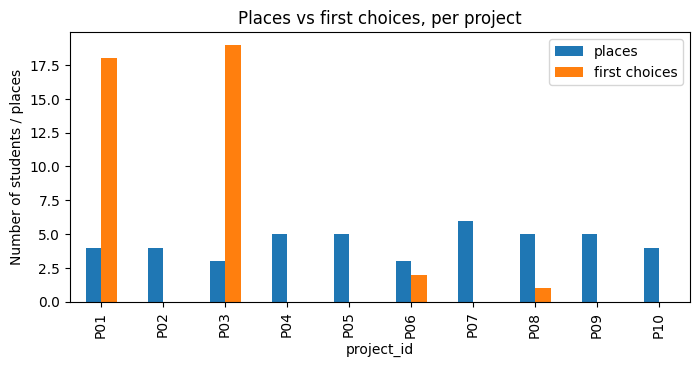

In [6]:
first = prefs[prefs["rank"] == 1]["project_id"].value_counts()
top3 = prefs[prefs["rank"] <= 3]["project_id"].value_counts()
listed = prefs["project_id"].value_counts()

demand = pd.DataFrame({"title": projects["title"], "places": projects["capacity"],
                       "first choices": first, "in top 3": top3, "listed at all": listed}).fillna(0)
demand = demand.astype({"first choices": int, "in top 3": int, "listed at all": int})
demand["first choices per place"] = (demand["first choices"] / demand["places"]).round(2)
print(demand)

demand[["places", "first choices"]].plot(kind="bar", figsize=(8, 3.5))
plt.ylabel("Number of students / places")
plt.title("Places vs first choices, per project")
plt.show()

Is the data repeatable?

In [7]:
def build(seed, n=40):
    rng = np.random.default_rng(seed)
    s = make_students(n, rng)
    f = fit_matrix(s, projects)
    p = make_preferences(f, projects, rng)
    return s, p

s1, p1 = build(42)
s2, p2 = build(42)
s3, p3 = build(7)
print("Same seed gives the same data:      ", s1.equals(s2) and p1.equals(p2))
print("Different seed gives different data:", not p1.equals(p3))

Same seed gives the same data:       True
Different seed gives different data: True


Save the data. Day 3's notebook will load these files.

In [8]:
students.to_csv("students.csv")
out = projects.copy()
out["needs"] = out["needs"].apply(lambda skills: ";".join(skills))
out.to_csv("projects.csv")
prefs.to_csv("preferences.csv", index=False)
print("Saved students.csv, projects.csv and preferences.csv")

Saved students.csv, projects.csv and preferences.csv
